## Вариант 10. Плотные сети: ёмкость, переобучение и регуляризация

**Цель:** исследовать связь «архитектура–данные–регуляризация».

1. На табличном датасете (например, синтетика с известной сложностью или небольшой реальный набор) обучите плотные сети разной ёмкости: 1×8, 2×32, 3×128, 5×256 нейронов на 5 seed для начальных весов.
2. Постройте **кривые обучения (train/val loss)** для каждой. Определите момент начала переобучения. Сведите результаты в таблицу: ёмкость vs val-метрика vs число параметров с усреднением по seed.
3. Исследуйте **регуляризацию**: L2, dropout (реализуйте сами с маской и масштабированием), early stopping. Сравните комбинации на самой «переобучающейся» архитектуре для всех seed из п.1.
4. Проведите эксперимент **«мало данных»**: обучите одну и ту же сеть на 100, 500, 5000 примерах. Покажите, как меняется разрыв train/val на seed из п.1.
5. **Аналитически** объясните: почему dropout эквивалентен ансамблю (в приближении)? Почему L2 «штрафует» большие веса и как это связано с гладкостью функции?
6. **Контрольные вопросы:**
   - как выбрать ёмкость под объём данных?
   - Что эффективнее при малых данных - уменьшение сети или регуляризация?
   - Есть ли «бесплатный завтрак - free lanch»?

## 1. Обучение сетей разной емкости

Я использовал готовый набор данных California Housing, в нем 20 640 строк и 8 признаков, где одна строка - группа кварталов, а ответ - медианная стоимость жилья в единицах 100к долларов.
[Взял отсюда](https://github.com/scikit-learn/scikit-learn/blob/main/sklearn/datasets/descr/california_housing.rst).

Признаки: доход жителей, возраст домов, число комнат и спален на домохозяйство,
население, число жителей на домохозяйство, широта и долгота.

Через `train_test_split` я выделил 5000 строк для обучения и 1000 для проверки (validation). Для сравнения архитектур взял первые 500 обучающих строк.

In [1]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

seeds = [0, 1, 2, 3, 4]
epochs = 200
lr = 0.001

In [2]:
data = fetch_california_housing()
X = data.data.astype(np.float32)
y = data.target.astype(np.float32).reshape(-1, 1)

# Логарифмируем число комнат, спален, население и число жильцов на домохозяйство.
X[:, [2, 3, 4, 5]] = np.log1p(X[:, [2, 3, 4, 5]])

X_pool, X_val_raw, y_pool, y_val_raw = train_test_split(
    X, y, train_size=5000, test_size=1000, random_state=17
)

print('Размер датасета:', X.shape)
print('Обучающий набор:', len(X_pool), 'Validation:', len(X_val_raw))
print('Признаки:', data.feature_names)

Размер датасета: (20640, 8)
Обучающий набор: 5000 Validation: 1000
Признаки: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


В 4х столбцах встречаются очень большие значения, поэтому я применил к ним
$\ln(1+x)$. Так большие значения меньше выделяются на фоне остальных.
После этого использовал StandardScaler:

$$x' = \frac{x-\mu}{s}.$$

Среднее $\mu$ и стандартное отклонение $s$ считаются по обучающей выборке.
Проверочные данные преобразуются с теми же $\mu$ и $s$.

In [3]:
def prepare_data(n):
    scaler = StandardScaler()
    x_train = scaler.fit_transform(X_pool[:n])
    x_val = scaler.transform(X_val_raw)
    return (torch.tensor(x_train, dtype=torch.float32), torch.tensor(y_pool[:n]),
            torch.tensor(x_val, dtype=torch.float32), torch.tensor(y_val_raw))

x_train, y_train, x_val, y_val = prepare_data(500)

### Сеть

У всех сетей 8 входов
и один выход (предсказанная стоимость). После каждого скрытого слоя стоит ReLU.

В слое с a входами и b нейронами будет ab весов и b смещений,
то есть (a+1)b параметров. Например для сети 1x8:

8 * 8 + 8 + 8 * 1 + 1 = 81 параметров.

Функцию dropout я написал здесь, она понадобится в пункте 3.
С вероятностью p выход нейрона обнуляется, а оставшиеся значения делятся на 1-p.
forward проходит по слоям и применяет dropout после ReLU только при обучении.

In [4]:
def dropout(x, p):
    mask = (torch.rand_like(x) >= p).float()
    return x * mask / (1 - p)

def make_model(hidden):
    layers = []
    inputs = 8
    for neurons in hidden:
        layers.append(nn.Linear(inputs, neurons))
        layers.append(nn.ReLU())
        inputs = neurons
    layers.append(nn.Linear(inputs, 1))
    return nn.Sequential(*layers)

def forward(model, x, p=0):
    for layer in model:
        x = layer(x)
        # При проверке dropout не нужен
        if isinstance(layer, nn.ReLU) and model.training and p > 0:
            x = dropout(x, p)
    return x

### Обучение
Я выбрал Adam с шагом 0.001 и 200 эпох. На каждой эпохе делается один шаг
по всей обучающей выборке. Ошибку считаю через MSE:

$$MSE = \frac1n\sum_{i=1}^n(\hat y_i-y_i)^2.$$

Для L2 к ошибке прибавляется $\frac\lambda2\sum w^2$ (без смещений).
Early stopping завершает обучение, если ошибка на validation не улучшается 20 эпох,
и возвращает веса с лучшим результатом.

В таблицах и на графиках везде обычная MSE: без штрафа L2 и с отключённым dropout, чтобы сравнивать ошибки разных моделей.

In [5]:
def train_model(hidden, seed, x_train, y_train, x_val, y_val,
                l2=0, p=0, early_stop=False):
    torch.manual_seed(seed)
    model = make_model(hidden)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    torch.manual_seed(10000 + seed)  # случайные маски dropout

    history = {'train': [], 'val': []}
    best_loss = float('inf')
    waiting = 0

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_fn(forward(model, x_train, p), y_train)
        if l2 > 0:
            for weight in model.parameters():
                if weight.ndim == 2:
                    loss = loss + l2 / 2 * (weight ** 2).sum()
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            train_loss = loss_fn(forward(model, x_train, p), y_train).item()
            val_loss = loss_fn(forward(model, x_val, p), y_val).item()
        history['train'].append(train_loss)
        history['val'].append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())
            waiting = 0
        else:
            waiting += 1
        if early_stop and waiting == 20:
            break

    if early_stop:
        model.load_state_dict(best_weights)
        with torch.no_grad():
            train_loss = loss_fn(forward(model, x_train, p), y_train).item()
            val_loss = loss_fn(forward(model, x_val, p), y_val).item()

    result = {'seed': seed, 'Параметры': sum(w.numel() for w in model.parameters()),
              'Train MSE': train_loss, 'Val MSE': val_loss,
              'Разрыв': val_loss - train_loss,
              'Эпоха min val': best_epoch, 'Эпоха остановки': epoch + 1}
    return history, result

### Запуск
Каждую сеть я обучил пять раз с seed от 0 до 4.
Обучающие и проверочные данные во всех запусках одинаковые, меняются начальные веса.

In [6]:
architectures = {'1x8': [8], '2x32': [32, 32],
                 '3x128': [128, 128, 128], '5x256': [256] * 5}
capacity_runs = {}
rows = []

for name, hidden in architectures.items():
    capacity_runs[name] = []
    for seed in seeds:
        history, result = train_model(hidden, seed, x_train, y_train, x_val, y_val)
        capacity_runs[name].append((history, result))
        rows.append({'Сеть': name, **result})
    print(name, 'готово')

1x8 готово


2x32 готово


3x128 готово


5x256 готово


## 2. Кривые обучения и сравнение результатов
В таблице mean - среднее по пяти запускам, std - стандартное отклонение.
Ошибки взяты после 200 эпох. На графиках показаны средние ошибки по эпохам.

Параметры Train MSE         Val MSE         Эпоха min val         
          first      mean     std    mean     std          mean      std
Сеть                                                                    
1x8          81    1.9024  0.3300  2.0079  0.3201         200.0   0.0000
2x32       1377    0.4057  0.0217  0.5278  0.0199         200.0   0.0000
3x128     34305    0.1749  0.0235  0.4280  0.0157         147.6  12.1367
5x256    265729    0.0407  0.0090  0.4949  0.0191          90.0   4.8477

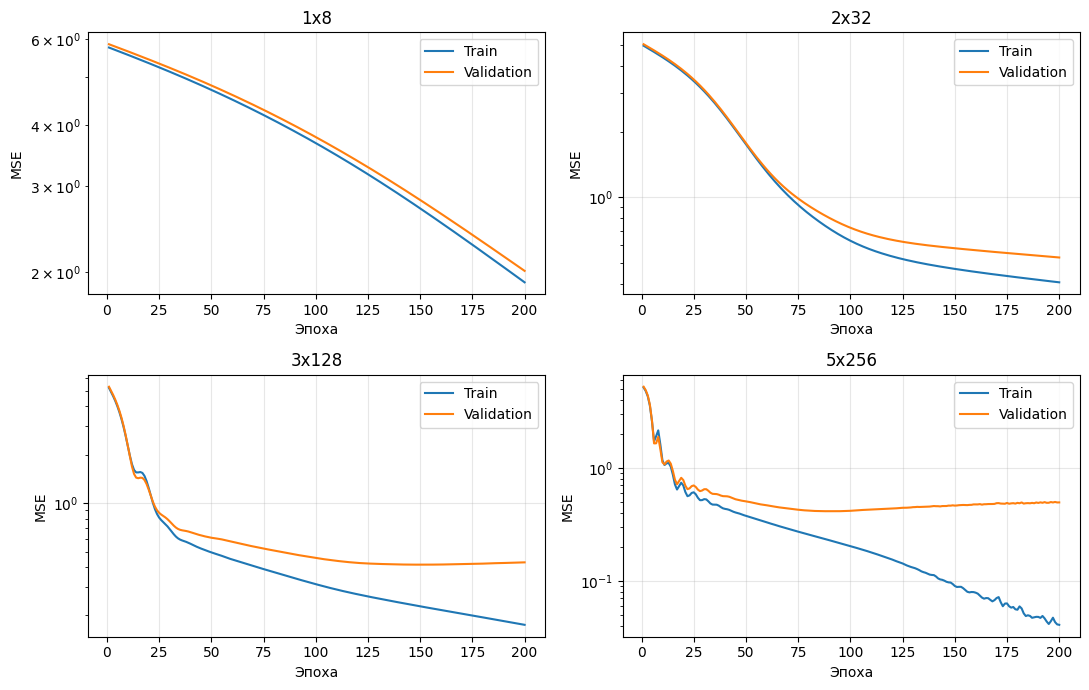

In [7]:
capacity_table = pd.DataFrame(rows)
display(capacity_table.groupby('Сеть', sort=False).agg({
    'Параметры': 'first', 'Train MSE': ['mean', 'std'],
    'Val MSE': ['mean', 'std'], 'Эпоха min val': ['mean', 'std']
}).round(4))
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, runs) in zip(axes.flat, capacity_runs.items()):
    train_curves = np.array([history['train'] for history, result in runs])
    val_curves = np.array([history['val'] for history, result in runs])
    ax.plot(range(1, epochs + 1), train_curves.mean(axis=0), label='Train')
    ax.plot(range(1, epochs + 1), val_curves.mean(axis=0), label='Validation')
    ax.set(title=name, xlabel='Эпоха', ylabel='MSE', yscale='log')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## Вывод
Без регуляризации лучшей оказалась сеть 3x128: средняя val MSE равна 0.4280.
У сети 5x256 ошибка на обучении гораздо ниже - 0.0407, но на проверке она выше - 0.4949.
То есть большая сеть лучше подстроилась под обучающие данные, но хуже предсказывает проверочные.

У 5x256 минимум ошибки на validation в среднем приходится примерно на 90ю эпоху,
а у 3x128 - примерно на 148ю. Дальше ошибка на обучении продолжает снижаться,
а на проверке уже не становится лучше. По этим минимумам и графикам я примерно
определяю начало переобучения.

У 1x8 и 2x32 минимум достигнут на последней, 200й эпохе.
Явного начала переобучения здесь не видно. У 1x8 обе ошибки высокие,
но по этому опыту нельзя сказать, что более долгое обучение ей не поможет.
Для проверки регуляризации я выбрал 5x256: у неё сильнее расходятся ошибки train и validation.

## 3. Регуляризация

Для сети 5x256 я сравнил L2, dropout, early stopping и две комбинации этих методов.
Для L2 взял $\lambda=0.0001$, для dropout - $p=0.2$.
Данные и пять seed остались теми же.

In [8]:
hidden = architectures['5x256']  # у этой сети сильнее переобучение
settings = [
    ('L2', 0.0001, 0, False),
    ('Dropout', 0, 0.2, False),
    ('Early stopping', 0, 0, True),
    ('Dropout + ES', 0, 0.2, True),
    ('L2 + Dropout + ES', 0.0001, 0.2, True)
]
reg_runs = {'Без регуляризации': capacity_runs['5x256']}

for name, l2, p, early_stop in settings:
    reg_runs[name] = []
    for seed in seeds:
        history, result = train_model(hidden, seed, x_train, y_train, x_val, y_val,
                                      l2=l2, p=p, early_stop=early_stop)
        reg_runs[name].append((history, result))
    print(name, 'готово')

rows = []
for name, runs in reg_runs.items():
    for history, result in runs:
        rows.append({'Метод': name, **result})
reg_table = pd.DataFrame(rows)
display(reg_table.groupby('Метод', sort=False).agg({
    'Train MSE': ['mean', 'std'], 'Val MSE': ['mean', 'std'],
    'Эпоха min val': 'mean', 'Эпоха остановки': 'mean'
}).round(4))

L2 готово


Dropout готово


Early stopping готово


Dropout + ES готово


L2 + Dropout + ES готово


Train MSE         Val MSE         Эпоха min val  \
                       mean     std    mean     std          mean   
Метод                                                               
Без регуляризации    0.0407  0.0090  0.4949  0.0191          90.0   
L2                   0.0407  0.0074  0.4932  0.0114          87.8   
Dropout              0.1747  0.0183  0.4742  0.0114         115.8   
Early stopping       0.2287  0.0091  0.4124  0.0076          90.0   
Dropout + ES         0.2347  0.0213  0.4236  0.0063         108.6   
L2 + Dropout + ES    0.2402  0.0233  0.4227  0.0071         104.6   

                  Эпоха остановки  
                             mean  
Метод                              
Без регуляризации           200.0  
L2                          200.0  
Dropout                     200.0  
Early stopping              110.0  
Dropout + ES                128.6  
L2 + Dropout + ES           124.6

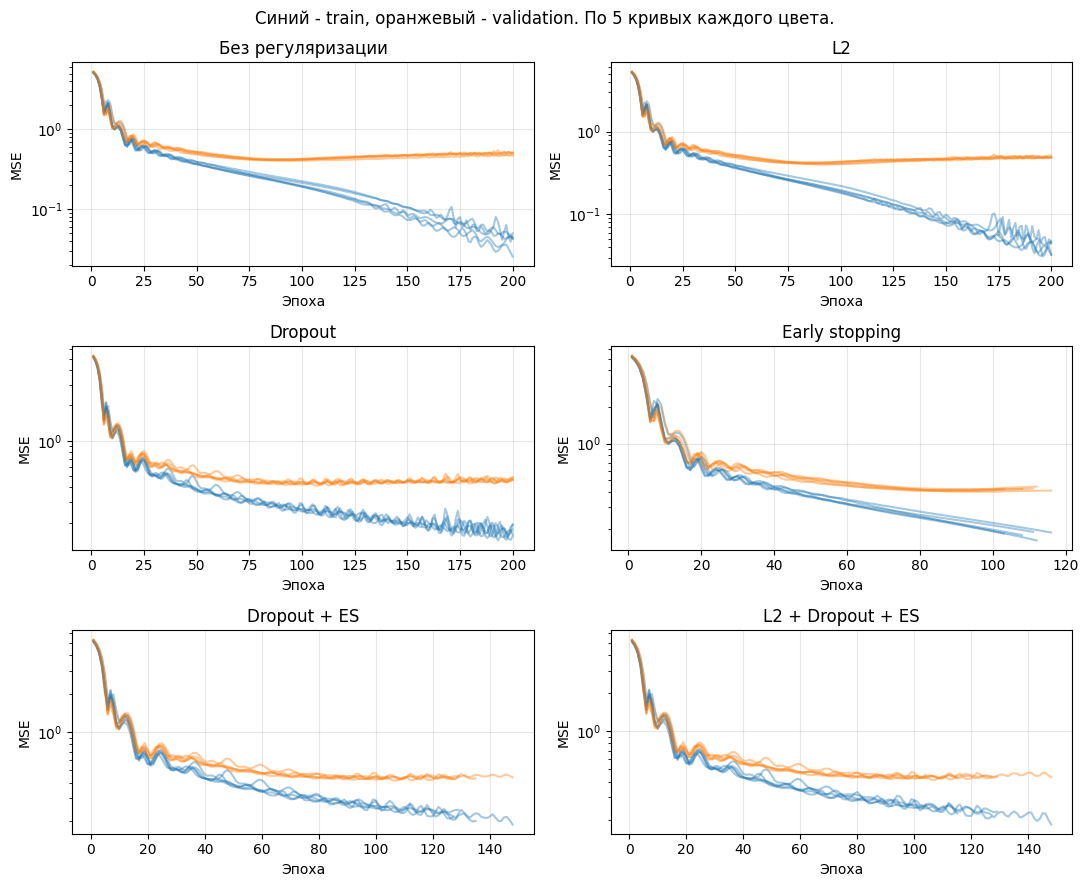

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(11, 9))
for ax, (name, runs) in zip(axes.flat, reg_runs.items()):
    for history, result in runs:
        steps = range(1, len(history['train']) + 1)
        ax.plot(steps, history['train'], color='tab:blue', alpha=0.4)
        ax.plot(steps, history['val'], color='tab:orange', alpha=0.4)
    ax.set(title=name, xlabel='Эпоха', ylabel='MSE', yscale='log')
    ax.grid(alpha=0.3)
plt.suptitle('Синий - train, оранжевый - validation. По 5 кривых каждого цвета.')
plt.tight_layout()
plt.show()

## Вывод
Лучше всего сработал early stopping: val MSE снизилась с 0.4949 до 0.4124.
В среднем обучение остановилось примерно на 110-й эпохе, а лучшие веса были получены на 90-й.

Dropout тоже помог, но слабее: ошибка стала 0.4742.

При λ = 0.0001 L2 заметно не улучшил результат. Ошибка на проверке изменилась с 0.4949 до 0.4932,
а на обучении ошибка после округления осталась той же - 0.0407.
Переобучение сохранилось. Возможно, штраф оказался слишком слабым, но для проверки
этого предположения нужно сравнить несколько значений λ. По одному коэффициенту
нельзя сделать вывод, что L2 вообще не помогает.

Все три метода вместе дали 0.4227 - хуже, чем один early stopping.
Получается, в этом опыте добавлять сразу все методы не было смысла.

## 4. Эксперимент «мало данных»

Здесь я обучил одну и ту же сеть 5x256 без регуляризации на 100, 500 и 5000 примерах.
Проверочная выборка, seed, шаг и число эпох остались прежними.
Результаты для 500 строк взял из первого опыта.

In [10]:
data_runs = {500: capacity_runs['5x256']}
for n in [100, 5000]:
    x_train_n, y_train_n, x_val_n, y_val_n = prepare_data(n)
    data_runs[n] = []
    for seed in seeds:
        history, result = train_model(architectures['5x256'], seed, x_train_n, y_train_n, x_val_n, y_val_n)
        data_runs[n].append((history, result))
    print(n, 'готово')

rows = []
for n in [100, 500, 5000]:
    for history, result in data_runs[n]:
        rows.append({'Размер train': n, **result})
data_table = pd.DataFrame(rows)
data_summary = data_table.groupby('Размер train')[['Train MSE', 'Val MSE', 'Разрыв']].agg(['mean', 'std'])
display(data_summary.round(4))

100 готово


5000 готово


Train MSE         Val MSE          Разрыв        
                  mean     std    mean     std    mean     std
Размер train                                                  
100             0.0001  0.0001  0.8061  0.1021  0.8060  0.1021
500             0.0407  0.0090  0.4949  0.0191  0.4542  0.0229
5000            0.2241  0.0113  0.3284  0.0044  0.1043  0.0086

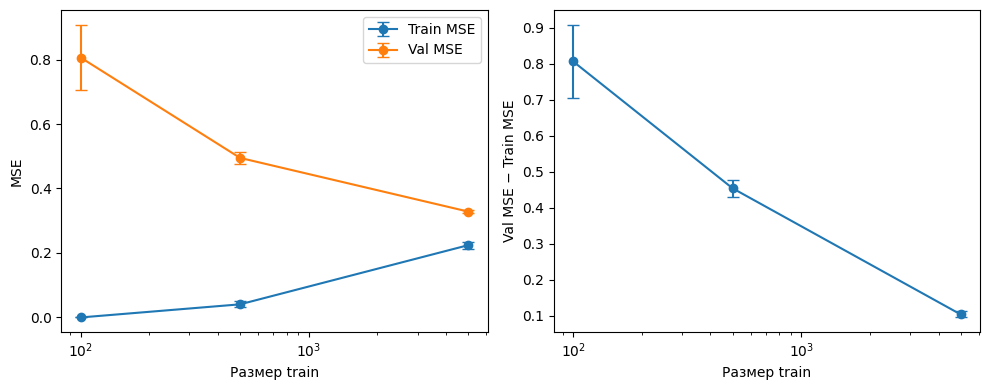

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for column in ['Train MSE', 'Val MSE']:
    axes[0].errorbar(data_summary.index, data_summary[(column, 'mean')],
                     yerr=data_summary[(column, 'std')], fmt='o-', capsize=4, label=column)
axes[0].set(xscale='log', xlabel='Размер train', ylabel='MSE')
axes[0].legend()
axes[1].errorbar(data_summary.index, data_summary[('Разрыв', 'mean')],
                 yerr=data_summary[('Разрыв', 'std')], fmt='o-', capsize=4)
axes[1].set(xscale='log', xlabel='Размер train', ylabel='Val MSE − Train MSE')
plt.tight_layout()
plt.show()

## Вывод
На 100 примерах сеть почти запомнила обучающую выборку: train MSE близка к нулю,
а val MSE равна 0.8061. На 5000 примерах val MSE стала 0.3284.
Разрыв между ошибками уменьшился с 0.8060 до 0.1043.

В этом опыте увеличение выборки помогло: сеть хуже запоминает отдельные примеры,
зато лучше предсказывает проверочные данные. При этом обучение на 5000 строках
требует больше вычислений, хотя число эпох то же.

## 5. Почему работают dropout и L2

### Dropout
При каждом шаге dropout случайно отключает часть нейронов. Получаются разные подсети, но веса у них общие. Поэтому это похоже на обучение ансамбля, хотя отдельные сети мы не создаём.

Обозначим выход нейрона через $h$, а случайную маску — через $m$. Маска равна 0, если нейрон отключён, и 1, если оставлен. Вероятность отключения — $p$. После dropout:

$$\tilde h=\frac{mh}{1-p}.$$

Например, если $h=4$ и $p=0.5$, получится либо 0, либо $4/0.5=8$. Оба исхода равновероятны, поэтому среднее равно $(0+8)/2=4$. Именно для сохранения среднего в коде есть деление на $1-p$.

При проверке dropout отключается и работают все нейроны. Это приближение к усреднению подсетей, из-за нелинейных функций активации результат не совпадает точно со средним предсказанием всех подсетей.

### L2
К ошибке добавляется $\frac\lambda2\sum w^2$. Большой вес даёт больший штраф,
а производная штрафа по весу равна $\lambda w$.
Для обычного градиентного спуска обновление будет таким:

$$w_{new}=w-\eta\left(\frac{\partial L}{\partial w}+\lambda w\right).$$

Возьмём $w=2$, $\eta=0.1$, $\partial L/\partial w=0.3$ и $\lambda=0.2$.
Без L2 новый вес равен $2-0.1\cdot0.3=1.97$.
С L2 получаем $2-0.1(0.3+0.2\cdot2)=1.93$.
В этом примере штраф сильнее уменьшил вес.

У нас используется Adam, поэтому само обновление сложнее.
Но к градиенту ошибки так же добавляется $\lambda w$.



### Как L2 связан с гладкостью

L2 штрафует большие веса. На простом примере $f(x)=wx$: если вход изменится на 0.01, то при весе 10 ответ изменится на 0.1, а при весе 1 - только на 0.01. Поэтому уменьшение весов может сделать предсказания менее чувствительными к небольшим изменениям входных данных. В этом смысле L2 помогает сделать функцию более гладкой.


### Пример early stopping

Пусть ошибки на validation по эпохам равны $[0.40,0.25,0.22,0.24,0.26]$.
Лучший результат - 0.22 на третьей эпохе. Если ждать две эпохи без улучшения,
обучение закончится на пятой и вернутся веса третьей.
В коде используется тот же принцип, только ожидание равно 20 эпохам.


## 6. Выводы

### Как выбрать ёмкость под объём данных?
Я бы начал с небольшой сети и посмотрел на ошибки
обучения и проверки. Если обе высокие, то можно увеличить сеть или обучать дольше.
Если ошибка на обучении падает, а на проверке растет, то стоит уменьшить сеть или добавить регуляризацию.
В моём опыте на 500 строках лучшей без регуляризации оказалась 3x128,
а для 5x256 помогла ранняя остановка.

### Что эффективнее при малых данных - уменьшение сети или регуляризация?
Нужно проверить оба варианта.
При 500 примерах 3x128 дала val MSE 0.4280, а 5x256 с early stopping - 0.4124.
Большая сеть немного точнее, но маленькая дешевле в обучении. При 100 примерах
регуляризацию отдельно не сравнивали, поэтому переносить туда этот вывод нельзя.

### Есть ли «бесплатный завтрак - free lunch»?
Нет метода, который был бы лучшим для любой задачи.
В этой работе early stopping помог сильнее, чем выбранные L2 и dropout,
но это не означает, что так будет на других данных.

Главный результат в том, что увеличение сети само по себе не улучшило предсказания.
Сеть 5x256 хорошо запоминала маленькую обучающую выборку, а ранняя остановка
и увеличение количества данных улучшили её результат на проверке.